In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import charge_trap_pot_model as ctm 
import time


np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)

ModCT = ctm.Image_charge_model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, t_ox=7, t_sige=48)


lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [5]:
H = ModCT.ysq_matrix()

In [6]:
print(H)

  (0, 0)	22500.0
  (1, 1)	22500.0
  (2, 2)	22500.0
  (3, 3)	22500.0
  (4, 4)	22500.0
  (5, 5)	22500.0
  (6, 6)	22500.0
  (7, 7)	22500.0
  (8, 8)	22500.0
  (9, 9)	22500.0
  (10, 10)	22500.0
  (11, 11)	22500.0
  (12, 12)	22500.0
  (13, 13)	22500.0
  (14, 14)	22500.0
  (15, 15)	22500.0
  (16, 16)	22500.0
  (17, 17)	22500.0
  (18, 18)	22500.0
  (19, 19)	22500.0
  (20, 20)	22500.0
  (21, 21)	22500.0
  (22, 22)	22500.0
  (23, 23)	22500.0
  (24, 24)	22500.0
  :	:
  (99575, 99575)	21025.0
  (99576, 99576)	21025.0
  (99577, 99577)	21025.0
  (99578, 99578)	21025.0
  (99579, 99579)	21025.0
  (99580, 99580)	21025.0
  (99581, 99581)	21025.0
  (99582, 99582)	21025.0
  (99583, 99583)	21025.0
  (99584, 99584)	21025.0
  (99585, 99585)	21025.0
  (99586, 99586)	21025.0
  (99587, 99587)	21025.0
  (99588, 99588)	21025.0
  (99589, 99589)	21025.0
  (99590, 99590)	21025.0
  (99591, 99591)	21025.0
  (99592, 99592)	21025.0
  (99593, 99593)	21025.0
  (99594, 99594)	21025.0
  (99595, 99595)	21025.0
  (99596, 9959

In [7]:
mu_array = ModCT.chem_pot()

In [8]:
mu_array.shape

(99600, 99600)

In [13]:
ysq_arr = ModCT.ysq_matrix()
ysq_arr.shape

(99600, 99600)

In [14]:
Hy = 1/4/hbm*MEFF_SM*OMEGA**2*ysq_arr

In [15]:
print(Hy.shape)

(99600, 99600)


In [18]:
mu_array.toarray()[:5,:5]

array([[1.97897247, 0.        , 0.        , 0.        , 0.        ],
       [0.        , 1.97897247, 0.        , 0.        , 0.        ],
       [0.        , 0.        , 1.97897247, 0.        , 0.        ],
       [0.        , 0.        , 0.        , 1.97897247, 0.        ],
       [0.        , 0.        , 0.        , 0.        , 1.97897247]])

In [22]:
Hy.toarray()[5:15,5:15]

array([[18.86355949,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        , 18.86355949,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        , 18.86355949,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , 18.86355949,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        , 18.86355949,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        18.86355949,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , 18.86355949,  0.        

In [23]:
1/4/hbm*MEFF_SM*OMEGA**2

0.0008383804218323495

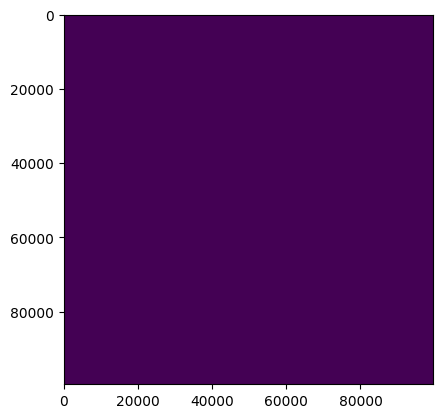

In [24]:
mu_array_dense = mu_array.toarray()
Hy_array_dense = Hy.toarray()
HA = mu_array_dense + Hy_array_dense
plt.imshow(HA)

In [25]:
HA.shape

(99600, 99600)

In [32]:
plt.imshow(Hy_array_dense)
plt.colorbar()

Error in callback <function flush_figures at 0x0000018AFAFD62A0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

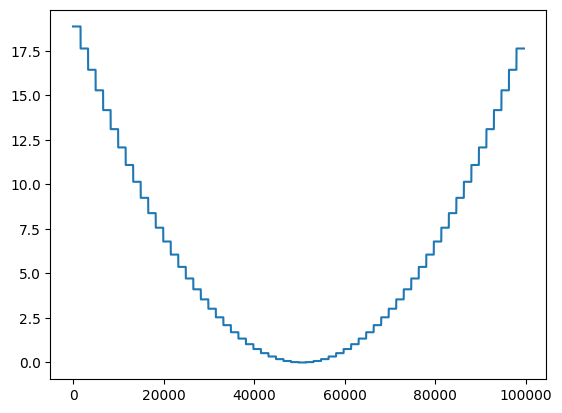

In [29]:
plt.plot(np.diag(Hy_array_dense))

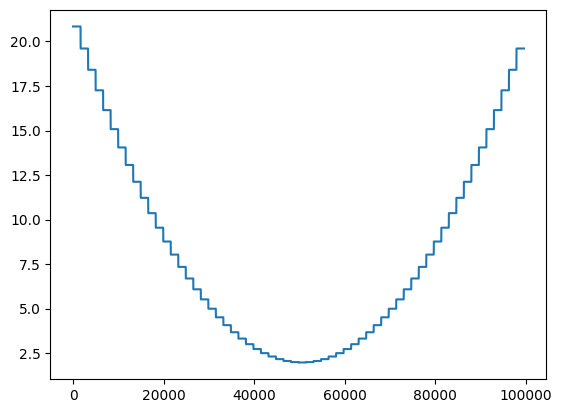

In [30]:
plt.plot(np.diag(HA))

KeyboardInterrupt: 

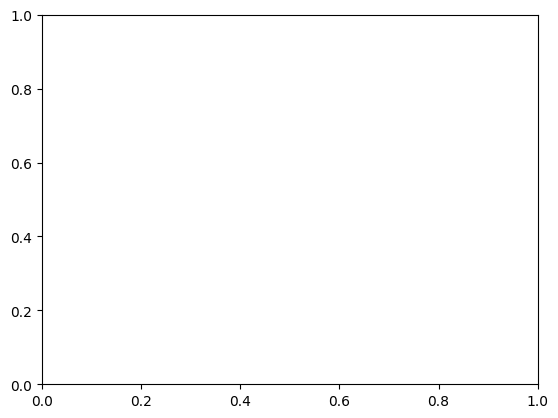

In [31]:
plt.plot(HA)

In [27]:

print(np.min(Hy_array_dense), np.max(Hy_array_dense))


0.0 18.863559491227864


In [28]:
Hy_array_dense[2005:2015, 2005:2015]

array([[17.62694837,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        , 17.62694837,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        , 17.62694837,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , 17.62694837,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        , 17.62694837,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
        17.62694837,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        , 17.62694837,  0.        